# Trabajo Práctico Integrador

## Port Log - Sprint 1

## Integrantes del grupo 07:

* Esteban Álvarez
* María Emilia Bazán
* Melina López
* Jorge Claure Endara
* Gustavo Zapana

## Repositorio GITHUB

https://github.com/estuchis21/Port_Log-Grupo_07.git



## Consideraciones Generales e Importantes

- Desarrollo base: Los puntos solicitados son la base del trabajo práctico. Es posible la ampliación sin restricciones del mismo.
- Para el traceo se deben agregar 1 [secrets](https://drlee.io/how-to-use-secrets-in-google-colab-for-api-key-protection-a-guide-for-openai-huggingface-and-c1ec9e1277e0) para la utilización de github.
  - GITHUB_TOKEN
- Organización del Notebook:
  - Agregar antes del ejercicio 01 una celda donde se importan todas librerías necesarias.
  - Utilizar un título para cada celda y escribir cada funcionalidad en una celda con título.
- La defensa es individual.
- Los grupos deben mantenerse a lo largo del trabajo integrador.
- La opción `DESACTIVAR_GIT_PUSH` solo será utilizada por los profesores.

## Versionado y Trabajo en Equipo


- Control de Versiones: Utilizar herramientas de versionado
- Colaboradores: Brindar acceso al repositorio a las siguientes cuentas:
  - lcd-had141@ugr.edu.ar
  - fpasinato@ugr.edu.ar
- La descripción del commit debe ser con el siguiente formato `"Día X: \<comentario del commit\>"`
- Changelog: Cada ejercicio/punto del trabajo práctico es considerado como un día distinto de trabajo. Debe quedar constancia en un archivo CHANGELOG.md de los cambios generados cada día. El changelog debe escribirse de tal forma que lo primero que se observe es el último cambio realizado, de esta forma apenas se abre el archivo se pueden leer los últimos cambios realizados. La forma de escritura debe ser un encabezado entre corchetes [Ejercicio X] y luego debajo los cambios realizado como bullets.
- El archivo README.md debe contener el sprint en el que nos encontramos y debe contener:
  - El objetivo.
  - La introducción y el contexto del sprint de trabajo.

## Criterios de evaluación

- Funcionalidad: el código debe ejecutar sin errores al dar "Ejecutar todo" (Ctrl+F9). Validar con Runtime -> Restart session and run all antes de entregar.
- Claridad: código organizado, nombres descriptivos, comentarios solo donde corresponde (funciones, clases, métodos). No se admite `git add .`.
- Estilo: [type hints](https://docs.python.org/3/library/typing.html), [pep8](https://peps.python.org/pep-0008/).

- Herramientas: librerías vistas en la cursada. Sin gdrive ni herramientas alternativas.

## Condiciones de Entrega
- Archivo `.ipynb`, ejecutado y con datos precargados, sobre copia de la plantilla original manteniendo la nomenclatura del nombre.
- Canal: aula virtual. Correo a lcd-had141@ugr.edu.ar solo si el plazo finalizó. No se aceptan enlaces.
- Los trabajos que no cumplan con los requisitos no serán tomados en cuenta como nota final. Solo serán corregidos y evaluados con nota para la devolución correspondiente. Se considera incumplimiento a:
  - Entregas fuera de término.
  - Trabajos que no se entreguen sobre la plantilla de trabajo estipulada.
  - Trabajos que no se ejecuten completos (que contengan errores intermedios al dar "Ejecutar todo").

---



# Objetivo

Aplicar conocimientos de versionado, organización y análisis exploratorio de datos con pandas sobre un dataset real de operaciones portuarias.

## Introducción y Contexto del problema

### Sprint 1

El Puerto Fluvial de Rosario es uno de los complejos portuarios más importantes de América del Sur, siendo el principal punto de exportación de granos y derivados de la Argentina. Diariamente ingresan y egresan decenas de buques de distintas banderas con cargas de diverso tipo.

El sistema de registro de movimientos portuarios fue migrado recientemente desde un sistema heredado de los años '90. Ese sistema acumuló durante décadas inconsistencias de formato en fechas, matrículas de buques y valores numéricos fuera de rango, generando registros que no pueden incorporarse directamente al nuevo sistema.

Nuestro equipo fue contratado para analizar y depurar los datos del sistema antiguo.

Descargar el dataset [port_movements](https://raw.githubusercontent.com/HAD141/datasets/refs/heads/main/TrabajosPracticos/port_log/port_movements.csv)  

`https://raw.githubusercontent.com/HAD141/datasets/refs/heads/main/TrabajosPracticos/port_log/port_movements.csv`

---

In [ ]:
#@title Importación de librerías
import base64
import os
import re
import subprocess
import warnings
from collections.abc import Callable, Iterable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

In [ ]:
#@title Configuración general del proyecto
NOMBRE_PROYECTO: str = "Port Log - Grupo 07"
SPRINT_ACTUAL: str = "Sprint 1"
RAMA_TRABAJO: str = "Sprint_1"
URL_REPOSITORIO: str = os.environ.get(
    "PORT_LOG_URL_REPOSITORIO",
    "https://github.com/estuchis21/Port_Log-Grupo_07.git",
)
DIRECTORIO_BASE: Path = Path(os.environ.get("PORT_LOG_DIRECTORIO_BASE",
                                            "/content"))
DIRECTORIO_REPO: Path = DIRECTORIO_BASE / (
    URL_REPOSITORIO.rstrip("/").rsplit("/", 1)[-1].removesuffix(".git")
)
URL_API_GITHUB: str = "https://api.github.com"
TIMEOUT_HTTP_SEGUNDOS: int = 30

DIR_PROYECTO: Path = DIRECTORIO_REPO / "port_log"
DIR_DATOS: Path = DIR_PROYECTO / "data"
DIR_RAW: Path = DIR_DATOS / "raw"
DIR_INTERIM: Path = DIR_DATOS / "interim"
DIR_PLOTS: Path = DIR_INTERIM / "plots"
DIR_PROCESSED: Path = DIR_DATOS / "processed"
DIR_REPORTS: Path = DIR_PROYECTO / "reports"
DIRECTORIOS_PROYECTO: tuple[Path, ...] = (
    DIR_RAW, DIR_INTERIM, DIR_PLOTS, DIR_PROCESSED, DIR_REPORTS,
)

URL_DATASET: str = (
    "https://raw.githubusercontent.com/HAD141/datasets/refs/heads/main/"
    "TrabajosPracticos/port_log/port_movements.csv"
)
NOMBRE_DATASET: str = "port_movements.csv"
RUTA_RAW: Path = DIR_RAW / NOMBRE_DATASET
RUTA_INTERIM: Path = DIR_INTERIM / NOMBRE_DATASET
RUTA_RESUMEN: Path = DIR_REPORTS / "summary_sprint1.csv"
RUTA_CONCLUSION: Path = DIR_REPORTS / "conclusion.md"
RUTA_README: Path = DIRECTORIO_REPO / "README.md"
RUTA_CHANGELOG: Path = DIRECTORIO_REPO / "CHANGELOG.md"

FORMATO_GRAFICOS: str = "jpg"
DPI_GRAFICOS: int = 150
RUTA_GRAFICO_TOP: Path = DIR_PLOTS / f"top_infractores.{FORMATO_GRAFICOS}"
RUTA_GRAFICO_TURNOS: Path = DIR_PLOTS / f"turnos.{FORMATO_GRAFICOS}"
RUTA_GRAFICO_MESES: Path = DIR_PLOTS / f"meses.{FORMATO_GRAFICOS}"
RUTA_GRAFICO_EXCESO: Path = (
    DIR_PLOTS / f"distribucion_exceso.{FORMATO_GRAFICOS}"
)
RUTA_GRAFICO_MUELLES: Path = (
    DIR_PLOTS / f"exceso_por_muelle.{FORMATO_GRAFICOS}"
)
RUTA_GRAFICO_FECHAS: Path = DIR_PLOTS / f"fechas_invalidas.{FORMATO_GRAFICOS}"

ESQUEMA_ESPERADO: dict[str, str] = {
    "movimiento_id": "object",
    "buque_id": "object",
    "matricula": "object",
    "radar_id": "object",
    "muelle": "object",
    "tipo_carga": "object",
    "origen": "object",
    "fecha_ingreso": "datetime64[ns]",
    "hora_ingreso": "timedelta64[ns]",
    "fecha_egreso": "datetime64[ns]",
    "hora_egreso": "timedelta64[ns]",
    "tonelaje_declarado": "float64",
    "velocidad_ingreso": "float64",
    "velocidad_maxima_muelle": "int64",
    "estado_despacho": "object",
}
COLUMNAS_FECHA: list[str] = [
    columna for columna, tipo in ESQUEMA_ESPERADO.items()
    if tipo.startswith("datetime")
]
COLUMNAS_HORA: list[str] = [
    columna for columna, tipo in ESQUEMA_ESPERADO.items()
    if tipo.startswith("timedelta")
]
COLUMNAS_NUMERICAS: list[str] = [
    columna for columna, tipo in ESQUEMA_ESPERADO.items()
    if tipo.startswith(("float", "int"))
]
PATRONES_TEXTO_VALIDO: dict[str, str] = {
    "movimiento_id": r"MOV-\d{5}",
    "buque_id": r"B-\d{3}",
    "matricula": r"[A-Z0-9]+(-[A-Z0-9]+)*",
    "radar_id": r"R-\d{2}",
    "muelle": r"MUELLE-[A-Z]",
    "tipo_carga": r"[A-Z]+( [A-Z]+)*",
    "origen": r"[A-Z]+( [A-Z]+)*",
    "estado_despacho": r"[A-Z]+(_[A-Z]+)*",
}

FECHA_INVALIDA: pd.Timestamp = pd.Timestamp("1900-01-01")
FORMATO_FECHA: str = "%Y-%m-%d"
FORMATOS_FECHA_ACEPTADOS: tuple[str, ...] = ("%Y-%m-%d", "%d/%m/%Y",
                                             "%d-%m-%Y")
HORA_INVALIDA: str = "00:00"
FORMATO_HORA: str = "%H:%M"
FORMATOS_HORA_ACEPTADOS: tuple[str, ...] = ("%H:%M", "%H:%M:%S",
                                            "%I:%M %p", "%H-%M")
PATRON_HORA: str = r"\d{1,2}[:-]\d{2}(:\d{2})?( ?[AP]M)?"
SUFIJO_VALIDEZ: str = "_valida"
PATRON_CARACTERES_ESPECIALES: str = r"[^A-Z0-9\s]"
PATRON_MATRICULA_VALIDA: str = r"[A-Z0-9]"

COLUMNAS_CRITICAS: tuple[str, ...] = (
    "matricula", "muelle", "velocidad_ingreso", "velocidad_maxima_muelle",
)
COLUMNAS_OUTLIERS: tuple[str, ...] = ("tonelaje_declarado",
                                      "velocidad_ingreso")
FACTOR_IQR: float = 1.5
UMBRAL_ZSCORE: float = 3.0
METODO_OUTLIERS: str = "IQR"
TOLERANCIA_VELOCIDAD: float = 0.05
DECIMALES: int = 2

FILAS_EXTREMOS: int = 5
FILAS_MUESTRA: int = 10
TOP_INFRACTORES: int = 10
HORAS_POR_DIA: int = 24
TURNOS: tuple[tuple[str, int], ...] = (
    ("Madrugada", 0), ("Mañana", 6), ("Tarde", 12), ("Noche", 18),
)
NOMBRES_MESES: tuple[str, ...] = (
    "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio",
    "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre",
)

ESTILO_ETIQUETA_EJE: dict[str, object] = {
    "fontsize": 11, "fontweight": "semibold", "labelpad": 10,
}
FUENTE_GRAFICOS: str = "Fuente de elaboración propia"

sns.set_theme(style="whitegrid")

In [ ]:
#@title Agregamos variables de entorno y secrets
import os
from google.colab import userdata

HOOKS="/tmp/.git-templates/hooks"

GITHUB_TOKEN = userdata.get('GITHUB_TOKEN')
try:
  DESACTIVAR_GIT_PUSH = bool(userdata.get('DESACTIVAR_GIT_PUSH'))
except userdata.SecretNotFoundError:
  DESACTIVAR_GIT_PUSH = False
os.environ['DESACTIVAR_GIT_PUSH'] = str(DESACTIVAR_GIT_PUSH)
os.environ['HOOKS'] = HOOKS

In [ ]:
#@title Creación del hook para que durante la corrección no se realicen modificaciones al repositorio
%%bash
mkdir -p $HOOKS
cat << EOF > $HOOKS/pre-push
#!/bin/sh
if [ "$DESACTIVAR_GIT_PUSH" = "'True'" ] || [ "$DESACTIVAR_GIT_PUSH" = "True" ]; then
    echo "[GIT HOOK - WARNING] Pushes are disabled for this repository."
    exit 1
fi
EOF

chmod +x $HOOKS/pre-push

In [ ]:
#@title Posicionarse en directorio de trabajo y agregar la siguiente configuración a git
if DESACTIVAR_GIT_PUSH:
  !git config --global core.hooksPath {HOOKS}

## Ejercicio 01

> Puntos: 1

Inicialización y configuración de la herramienta de versionado sobre la rama `Sprint_1`.

La estructura de directorios es:

```
├── port_log
│   ├── data
│   │   ├── interim    (datasets procesados en pasos intermedios)
│   │   │   ├── plots
│   │   ├── processed  (datasets finales para otra aplicación)
│   │   ├── raw        (datasets en crudo)
│   ├── reports        (resúmenes estadísticos generados)
```

In [ ]:
#@title Funciones auxiliares de versionado
def _parametros_autenticacion() -> list[str]:
    """Arma el encabezado de autenticación de GitHub para un único comando.

    Se pasa con ``git -c`` para que el token no quede guardado en
    ``.git/config`` ni aparezca en la URL del remoto.
    """
    if not GITHUB_TOKEN:
        return []
    credencial = base64.b64encode(
        f"x-access-token:{GITHUB_TOKEN}".encode()).decode()
    return ["-c", "http.https://github.com/.extraheader="
                  f"AUTHORIZATION: basic {credencial}"]


def ejecutar_git(*argumentos: str, directorio: Path = DIRECTORIO_REPO,
                 autenticar: bool = False,
                 verificar: bool = True) -> subprocess.CompletedProcess:
    """Ejecuta un comando git y lanza un error legible si falla."""
    comando = ["git",
               *(_parametros_autenticacion() if autenticar else []),
               *argumentos]
    resultado = subprocess.run(comando, cwd=directorio, capture_output=True,
                               text=True)
    if verificar and resultado.returncode != 0:
        raise RuntimeError(f"Falló 'git {' '.join(argumentos)}':\n"
                           f"{resultado.stderr.strip()}")
    return resultado


def rama_remota_existe(rama: str) -> bool:
    """Indica si la rama existe en el repositorio remoto."""
    salida = ejecutar_git("ls-remote", "--heads", "origin", rama,
                          autenticar=True).stdout
    return bool(salida.strip())


def rama_local_existe(rama: str) -> bool:
    """Indica si la rama existe en el repositorio local."""
    return ejecutar_git("rev-parse", "--verify", "--quiet",
                        f"refs/heads/{rama}", verificar=False).returncode == 0


def configurar_identidad_git() -> None:
    """Configura autor y email del repositorio con la cuenta dueña del token.

    Si el token no permite consultar la API se usa una identidad genérica
    del proyecto, así el notebook se ejecuta completo igualmente.
    """
    try:
        respuesta = requests.get(
            f"{URL_API_GITHUB}/user",
            headers={"Authorization": f"Bearer {GITHUB_TOKEN}"},
            timeout=TIMEOUT_HTTP_SEGUNDOS,
        )
        respuesta.raise_for_status()
        cuenta = respuesta.json()
        nombre = cuenta.get("name") or cuenta["login"]
        email = (f"{cuenta['id']}+{cuenta['login']}"
                 "@users.noreply.github.com")
    except (requests.RequestException, KeyError):
        nombre = NOMBRE_PROYECTO
        email = "port-log@users.noreply.github.com"
    ejecutar_git("config", "user.name", nombre)
    ejecutar_git("config", "user.email", email)
    print(f"[GIT] Autor de los commits: {nombre} <{email}>")


def preparar_repositorio(rama: str) -> None:
    """Clona (o actualiza) el repositorio y deja activa la rama de trabajo."""
    if (DIRECTORIO_REPO / ".git").exists():
        ejecutar_git("fetch", "origin", autenticar=True)
    else:
        DIRECTORIO_BASE.mkdir(parents=True, exist_ok=True)
        ejecutar_git("clone", URL_REPOSITORIO, str(DIRECTORIO_REPO),
                     directorio=DIRECTORIO_BASE, autenticar=True)
    configurar_identidad_git()
    remota = rama_remota_existe(rama)
    if rama_local_existe(rama):
        ejecutar_git("checkout", rama)
        if remota:
            ejecutar_git("pull", "--rebase", "--autostash", "origin", rama,
                         autenticar=True)
    elif remota:
        ejecutar_git("checkout", "-b", rama, "--track", f"origin/{rama}")
    else:
        ejecutar_git("checkout", "-b", rama)


def _leer_changelog() -> tuple[list[str], dict[int, list[str]]]:
    """Separa el CHANGELOG en encabezado y bloques por ejercicio."""
    encabezado: list[str] = []
    bloques: dict[int, list[str]] = {}
    actual: int | None = None
    texto = (RUTA_CHANGELOG.read_text(encoding="utf-8")
             if RUTA_CHANGELOG.exists() else "")
    for linea in texto.splitlines():
        coincidencia = re.fullmatch(r"\[Ejercicio (\d+)\]", linea.strip())
        if coincidencia:
            actual = int(coincidencia.group(1))
            bloques[actual] = []
        elif actual is not None and linea.strip():
            bloques[actual].append(linea.rstrip())
        elif actual is None and linea.strip():
            encabezado.append(linea.rstrip())
    return encabezado, bloques


def registrar_en_changelog(ejercicio: int, cambios: Iterable[str]) -> None:
    """Agrega o reemplaza el bloque del ejercicio dejando primero el último."""
    encabezado, bloques = _leer_changelog()
    bloques[ejercicio] = [f"- {cambio}" for cambio in cambios]
    secciones = ["\n".join(encabezado or [f"# Changelog - {NOMBRE_PROYECTO}"])]
    for numero in sorted(bloques, reverse=True):
        secciones.append("\n".join([f"[Ejercicio {numero:02d}]",
                                    *bloques[numero]]))
    RUTA_CHANGELOG.write_text("\n\n".join(secciones) + "\n", encoding="utf-8")


def subir_cambios(rama: str) -> None:
    """Sube la rama al remoto salvo que el push esté desactivado."""
    if DESACTIVAR_GIT_PUSH:
        print("[GIT] Push desactivado: el commit queda solo en local.")
        return
    if rama_remota_existe(rama):
        ejecutar_git("pull", "--rebase", "--autostash", "origin", rama,
                     autenticar=True)
    ejecutar_git("push", "--set-upstream", "origin", rama, autenticar=True)
    print(f"[GIT] Rama '{rama}' subida a origin.")


def registrar_dia(dia: int, descripcion: str, cambios: Iterable[str],
                  archivos: Iterable[Path] = ()) -> None:
    """Registra un día de trabajo: CHANGELOG, commit y push.

    Se agregan solo los archivos indicados (nunca ``git add .``).
    """
    registrar_en_changelog(dia, cambios)
    rutas = [str(Path(archivo).relative_to(DIRECTORIO_REPO).as_posix())
             for archivo in (*archivos, RUTA_CHANGELOG)]
    ejecutar_git("add", "--", *rutas)
    sin_cambios = ejecutar_git("diff", "--cached", "--quiet",
                               verificar=False).returncode == 0
    if sin_cambios:
        print(f"[GIT] Día {dia}: no hay cambios nuevos para commitear.")
        return
    ejecutar_git("commit", "-m", f"Día {dia}: {descripcion}")
    print(f"[GIT] Commit 'Día {dia}: {descripcion}' creado.")
    subir_cambios(RAMA_TRABAJO)

In [ ]:
#@title Clonar el repositorio y posicionarse en la rama de trabajo
preparar_repositorio(RAMA_TRABAJO)
os.chdir(DIRECTORIO_REPO)
print(f"Directorio de trabajo: {Path.cwd()}")
rama_activa = ejecutar_git("branch", "--show-current").stdout.strip()
print(f"Rama activa: {rama_activa}")

[GIT] Autor de los commits: Melina Lopez <227845157+meliilopez@users.noreply.github.com>
Directorio de trabajo: /content/Port_Log-Grupo_07
Rama activa: Sprint_1


In [ ]:
#@title Posicionarse en directorio de trabajo y agregar la siguiente configuración a git
if DESACTIVAR_GIT_PUSH:
  !git config --global core.hooksPath {HOOKS}

In [ ]:
#@title Crear la estructura de directorios del proyecto
def crear_estructura(directorios: Iterable[Path]) -> list[Path]:
    """Crea los directorios y un ``.gitkeep`` para que git los versione."""
    marcadores = []
    for directorio in directorios:
        directorio.mkdir(parents=True, exist_ok=True)
        marcador = directorio / ".gitkeep"
        marcador.touch(exist_ok=True)
        marcadores.append(marcador)
    return marcadores


marcadores_estructura = crear_estructura(DIRECTORIOS_PROYECTO)
for directorio in DIRECTORIOS_PROYECTO:
    print(f" - {directorio.relative_to(DIRECTORIO_REPO).as_posix()}")

 - port_log/data/raw
 - port_log/data/interim
 - port_log/data/interim/plots
 - port_log/data/processed
 - port_log/reports


In [ ]:
#@title Generar el README.md del sprint
OBJETIVO_SPRINT: str = (
    "Aplicar conocimientos de versionado, organización y análisis "
    "exploratorio de datos con pandas sobre un dataset real de operaciones "
    "portuarias."
)
CONTEXTO_SPRINT: str = (
    "El Puerto Fluvial de Rosario es uno de los complejos portuarios más "
    "importantes de América del Sur, siendo el principal punto de "
    "exportación de granos y derivados de la Argentina. Diariamente "
    "ingresan y egresan decenas de buques de distintas banderas con cargas "
    "de diverso tipo.\n\n"
    "El sistema de registro de movimientos portuarios fue migrado "
    "recientemente desde un sistema heredado de los años '90. Ese sistema "
    "acumuló durante décadas inconsistencias de formato en fechas, "
    "matrículas de buques y valores numéricos fuera de rango, generando "
    "registros que no pueden incorporarse directamente al nuevo sistema.\n\n"
    "Nuestro equipo fue contratado para analizar y depurar los datos del "
    "sistema antiguo."
)


def generar_readme(ruta: Path) -> None:
    """Escribe el README con el sprint actual, su objetivo y su contexto."""
    estructura = "\n".join(
        f"- `{directorio.relative_to(DIRECTORIO_REPO).as_posix()}`"
        for directorio in DIRECTORIOS_PROYECTO
    )
    contenido = (
        f"# {NOMBRE_PROYECTO}\n\n"
        f"## {SPRINT_ACTUAL}\n\n"
        f"### Objetivo\n\n{OBJETIVO_SPRINT}\n\n"
        f"### Introducción y contexto\n\n{CONTEXTO_SPRINT}\n\n"
        f"### Estructura del proyecto\n\n{estructura}\n"
    )
    ruta.write_text(contenido, encoding="utf-8")


generar_readme(RUTA_README)
display(Markdown(RUTA_README.read_text(encoding="utf-8")))

# Port Log - Grupo 07

## Sprint 1

### Objetivo

Aplicar conocimientos de versionado, organización y análisis exploratorio de datos con pandas sobre un dataset real de operaciones portuarias.

### Introducción y contexto

El Puerto Fluvial de Rosario es uno de los complejos portuarios más importantes de América del Sur, siendo el principal punto de exportación de granos y derivados de la Argentina. Diariamente ingresan y egresan decenas de buques de distintas banderas con cargas de diverso tipo.

El sistema de registro de movimientos portuarios fue migrado recientemente desde un sistema heredado de los años '90. Ese sistema acumuló durante décadas inconsistencias de formato en fechas, matrículas de buques y valores numéricos fuera de rango, generando registros que no pueden incorporarse directamente al nuevo sistema.

Nuestro equipo fue contratado para analizar y depurar los datos del sistema antiguo.

### Estructura del proyecto

- `port_log/data/raw`
- `port_log/data/interim`
- `port_log/data/interim/plots`
- `port_log/data/processed`
- `port_log/reports`


In [ ]:
#@title Registrar el Día 1 en git
registrar_dia(
    1,
    "Inicialización del repositorio y estructura del proyecto",
    [
        f"Configuración de git sobre la rama `{RAMA_TRABAJO}`.",
        "Creación de la estructura de directorios `port_log` con `.gitkeep`.",
        "README.md con el sprint, objetivo, introducción y contexto.",
        "CHANGELOG.md ordenado del último cambio al primero.",
    ],
    [RUTA_README, *marcadores_estructura],
)

[GIT] Día 1: no hay cambios nuevos para commitear.


## Ejercicio 02

> Puntos: 1

- Descargar el dataset raw y almacenarlo en `port_log/data/raw/port_movements.csv`.


In [ ]:
#@title Descargar el dataset crudo
def descargar_archivo(url: str, destino: Path) -> Path:
    """Descarga un archivo sin modificarlo y lo guarda en ``destino``."""
    respuesta = requests.get(url, timeout=TIMEOUT_HTTP_SEGUNDOS)
    respuesta.raise_for_status()
    destino.parent.mkdir(parents=True, exist_ok=True)
    destino.write_bytes(respuesta.content)
    return destino


descargar_archivo(URL_DATASET, RUTA_RAW)
df_raw: pd.DataFrame = pd.read_csv(RUTA_RAW)
print(f"Dataset guardado en {RUTA_RAW.relative_to(DIRECTORIO_REPO).as_posix()}"
      f" ({df_raw.shape[0]} filas x {df_raw.shape[1]} columnas)")

Dataset guardado en port_log/data/raw/port_movements.csv (1500 filas x 15 columnas)


- Mostrar las 5 primeras y las 5 últimas filas en una única salida.


In [ ]:
#@title Primeras y últimas filas del dataset
pd.concat([df_raw.head(FILAS_EXTREMOS), df_raw.tail(FILAS_EXTREMOS)])

,movimiento_id,buque_id,matricula,radar_id,muelle,tipo_carga,origen,fecha_ingreso,hora_ingreso,fecha_egreso,hora_egreso,tonelaje_declarado,velocidad_ingreso,velocidad_maxima_muelle,estado_despacho
0,MOV-00001,B-008,MSC-GENOVA,R-05,MUELLE-B,TRIGO,MONTEVIDEO,2023-04-24,13:02,2023-04-24,10:55 PM,3874.34,6.3,10,DESPACHADO
1,MOV-00002,B-025,MAERSK-LIMA,R-06,MUELLE-C,HARINA,SANTA FE,2020-06-10,17:18,2020-06-12,7:05,1856.07,10.2,12,RECHAZADO
2,MOV-00003,B-011,ZIM-NORTE,R-04,MUELLE-B,MINERALES,ROTTERDAM,32/13/2021,21:20,2021-03-26,19:01,6711.61,11.7,15,EN_REVISION
3,MOV-00004,B-038,NaN,R-06,MUELLE-B,MAIZ,HAMBURG,2023-07-09,5:50,2023-07-11,1:20,5086.61,6.0,10,DESPACHADO
4,MOV-00005,B-017,ONE-PLATA,R-03,MUELLE-E,SOJA,VALPARAISO,2024-05-13,16:58,2024-05-13,2:16,6166.47,16.2,15,PENDIENTE
1495,MOV-01496,B-019,HAPAG-SUR,R-01,MUELLE-A,MAIZ,SHANGHAI,2022-07-07,4:19,2022-07-08,23:19,4692.60,11.6,15,DESPACHADO
1496,MOV-01497,B-035,YANG-ESTE,R-01,muelle e!!,SOJA,SANTA FE,2021-06-30,20:29,2021-07-02,NaN,4523.07,6.5,10,DESPACHADO
1497,MOV-01498,B-012,ONE-PLATA,R-08,MUELLE-D,ACEITE,HAMBURG,2022-11-08,13:35,2022-11-10,02:45 AM,4845.04,9.3,12,EN_REVISION
1498,MOV-01499,B-026,PIL-SANTA,R-06,MUELLE-B,TRIGO,VALPARAISO,2021-06-27,20:40,2021-06-30,10:20 PM,4197.51,10.1,15,RECHAZADO
1499,MOV-01500,B-008,@#$%,R-08,MUELLE-C,ACEITE,SHANGHAI,2023-09-24,6:15,2023-09-25,21:53,5811.38,15.4,10,EN_REVISION


- Analizar tipos de datos e indicar cuáles columnas requieren conversión.


In [ ]:
#@title Análisis de tipos de datos
def comparar_tipos(datos: pd.DataFrame,
                   esquema: dict[str, str]) -> pd.DataFrame:
    """Compara el tipo inferido por pandas con el tipo esperado por columna."""
    tipos = pd.DataFrame({
        "tipo_actual": datos.dtypes.astype(str),
        "tipo_esperado": pd.Series(esquema),
    })
    tipos["requiere_conversion"] = (
        tipos["tipo_actual"] != tipos["tipo_esperado"])
    return tipos.rename_axis("columna")


tipos_datos = comparar_tipos(df_raw, ESQUEMA_ESPERADO)
columnas_a_convertir = tipos_datos.index[
    tipos_datos["requiere_conversion"]].tolist()
print(f"Columnas que requieren conversión: {', '.join(columnas_a_convertir)}")
tipos_datos

Columnas que requieren conversión: fecha_ingreso, hora_ingreso, fecha_egreso, hora_egreso


,tipo_actual,tipo_esperado,requiere_conversion
columna,,,
movimiento_id,object,object,False
buque_id,object,object,False
matricula,object,object,False
radar_id,object,object,False
muelle,object,object,False
tipo_carga,object,object,False
origen,object,object,False
fecha_ingreso,object,datetime64[ns],True
hora_ingreso,object,timedelta64[ns],True


- Contar los valores nulos y mostrarlos ordenados de mayor a menor.


In [ ]:
#@title Conteo de valores nulos
(df_raw.isna().sum()
 .sort_values(ascending=False)
 .rename("valores_nulos")
 .to_frame()
 .rename_axis("columna"))

,valores_nulos
columna,
velocidad_ingreso,82
tonelaje_declarado,69
radar_id,65
estado_despacho,58
matricula,56
hora_egreso,34
movimiento_id,0
origen,0
tipo_carga,0


- Calcular y mostrar el porcentaje de valores correctos por cada columna. Por ejemplo, si en una fila de fechas tengo una letra, entonces la contabilizo como valor incorrecto. Los valores nulos son considerados como valores incorrectos.

  Generar una única salida y debe tener el siguiente formato:
```
Completitud del dataset:
 - nombre_columna_1: XX.XX% completa
 - nombre_columna_2: XX.XX% completa
 - ...
```

In [ ]:
#@title Funciones de validación y normalización
def parsear_fechas(serie: pd.Series,
                   formatos: Iterable[str] = FORMATOS_FECHA_ACEPTADOS
                   ) -> pd.Series:
    """Convierte texto a fecha probando cada formato; lo inválido es NaT."""
    texto = serie.astype("string").str.strip()
    fechas = pd.Series(pd.NaT, index=serie.index, dtype="datetime64[ns]")
    for formato in formatos:
        fechas = fechas.fillna(
            pd.to_datetime(texto, format=formato, errors="coerce"))
    return fechas


def parsear_horas(serie: pd.Series,
                  formatos: Iterable[str] = FORMATOS_HORA_ACEPTADOS,
                  patron: str = PATRON_HORA) -> pd.Series:
    """Convierte texto a hora del día (timedelta); lo inválido es NaT.

    Antes de parsear se exige el patrón ``patron`` para descartar horas
    truncadas como ``18:5``, que son ambiguas.
    """
    texto = serie.astype("string").str.strip().str.upper()
    candidatas = texto.where(texto.str.fullmatch(patron).fillna(False))
    horas = pd.Series(pd.NaT, index=serie.index, dtype="datetime64[ns]")
    for formato in formatos:
        horas = horas.fillna(
            pd.to_datetime(candidatas, format=formato, errors="coerce"))
    return horas - horas.dt.normalize()


def formatear_horas(horas: pd.Series) -> pd.Series:
    """Convierte horas del día (timedelta) a texto en formato de 24 hs."""
    return (pd.Timestamp(0) + horas).dt.strftime(FORMATO_HORA)


def normalizar_texto(serie: pd.Series) -> pd.Series:
    """Pasa a mayúsculas, cambia guiones por espacios y quita especiales.

    Los espacios repetidos quedan en uno solo y se recortan los bordes.
    """
    return (serie.astype("string").str.upper()
            .str.replace("-", " ", regex=False)
            .str.replace(PATRON_CARACTERES_ESPECIALES, "", regex=True)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip())


def es_texto_valido(patron: str) -> Callable[[pd.Series], pd.Series]:
    """Crea un validador que exige que el texto cumpla ``patron``."""
    def validar(serie: pd.Series) -> pd.Series:
        return (serie.astype("string").str.fullmatch(patron)
                .fillna(False).astype(bool))
    return validar


def es_numero_positivo(serie: pd.Series) -> pd.Series:
    """Valida que el valor sea numérico y mayor a cero."""
    return pd.to_numeric(serie, errors="coerce").gt(0)


VALIDADORES: dict[str, Callable[[pd.Series], pd.Series]] = {
    **{columna: es_texto_valido(patron)
       for columna, patron in PATRONES_TEXTO_VALIDO.items()},
    **{columna: lambda serie: parsear_fechas(serie).notna()
       for columna in COLUMNAS_FECHA},
    **{columna: lambda serie: parsear_horas(serie).notna()
       for columna in COLUMNAS_HORA},
    **{columna: es_numero_positivo for columna in COLUMNAS_NUMERICAS},
}

In [ ]:
#@title Completitud del dataset
def calcular_completitud(datos: pd.DataFrame) -> pd.Series:
    """Porcentaje de valores correctos por columna (nulos = incorrectos)."""
    return pd.Series({
        columna: VALIDADORES.get(
            columna, lambda serie: serie.notna())(datos[columna]).mean() * 100
        for columna in datos.columns
    })


completitud = calcular_completitud(df_raw)
print("Completitud del dataset:")
for columna, porcentaje in completitud.items():
    print(f" - {columna}: {porcentaje:.2f}% completa")

Completitud del dataset:
 - movimiento_id: 100.00% completa
 - buque_id: 100.00% completa
 - matricula: 90.53% completa
 - radar_id: 95.67% completa
 - muelle: 95.20% completa
 - tipo_carga: 100.00% completa
 - origen: 100.00% completa
 - fecha_ingreso: 96.47% completa
 - hora_ingreso: 93.53% completa
 - fecha_egreso: 97.53% completa
 - hora_egreso: 88.60% completa
 - tonelaje_declarado: 93.93% completa
 - velocidad_ingreso: 94.53% completa
 - velocidad_maxima_muelle: 100.00% completa
 - estado_despacho: 96.13% completa


In [ ]:
#@title Registrar el Día 2 en git
registrar_dia(
    2,
    "Descarga del dataset y análisis exploratorio inicial",
    [
        "Descarga del dataset crudo en "
        "`port_log/data/raw/port_movements.csv`.",
        "Visualización de las primeras y últimas filas.",
        "Comparación de tipos inferidos contra el esquema esperado.",
        "Conteo de valores nulos ordenado de mayor a menor.",
        "Completitud por columna validando formato además de nulos.",
    ],
    [RUTA_RAW],
)

[GIT] Día 2: no hay cambios nuevos para commitear.


## Ejercicio 03

> Puntos: 2

Utilizando Pandas, realizar la limpieza y normalización de datos:

- Normalizar fechas de ingreso y egreso al formato `YYYY-MM-DD`. Las fechas inválidas deben completarse con `1900-01-01`.

  Mostrar las 10 primeras fechas de ingreso.



In [ ]:
#@title Normalización de fechas
df_limpio: pd.DataFrame = df_raw.copy()
for columna in COLUMNAS_FECHA:
    df_limpio[columna] = parsear_fechas(df_raw[columna]).fillna(FECHA_INVALIDA)

pd.DataFrame({
    "fecha_ingreso_original": df_raw["fecha_ingreso"],
    "fecha_ingreso": df_limpio["fecha_ingreso"].dt.strftime(FORMATO_FECHA),
}).head(FILAS_MUESTRA)

,fecha_ingreso_original,fecha_ingreso
0,2023-04-24,2023-04-24
1,2020-06-10,2020-06-10
2,32/13/2021,1900-01-01
3,2023-07-09,2023-07-09
4,2024-05-13,2024-05-13
5,2022-11-25,2022-11-25
6,2022-08-14,2022-08-14
7,2022-02-15,2022-02-15
8,32/13/2021,1900-01-01
9,2022-01-26,2022-01-26


- Normalizar las horas con el formato de 24hs. Las horas inválidas deben completarse con `00:00`.

  Mostrar los datos de las 10 primeras horas inválidas.


In [ ]:
# @title Normalización de horas y visualización de muestras inválidas
for columna in COLUMNAS_HORA:
    horas_dt = parsear_horas(df_raw[columna])
    df_limpio[f"{columna}{SUFIJO_VALIDEZ}"] = horas_dt.notna()
    horas_str = (pd.Timestamp("1900-01-01") + horas_dt).dt.strftime(
        FORMATO_HORA
    )
    df_limpio[columna] = horas_str.fillna(HORA_INVALIDA)

columnas_validez_hora = [
    f"{columna}{SUFIJO_VALIDEZ}" for columna in COLUMNAS_HORA
]
hora_invalida = ~df_limpio[columnas_validez_hora].all(axis=1)

df_raw.loc[hora_invalida, ["movimiento_id", *COLUMNAS_HORA]].join(
    df_limpio.loc[hora_invalida, COLUMNAS_HORA], rsuffix="_normalizada"
).head(FILAS_MUESTRA)

,movimiento_id,hora_ingreso,hora_egreso,hora_ingreso_normalizada,hora_egreso_normalizada
9,MOV-00010,AB:CD,13:30,00:00,13:30
22,MOV-00023,4:17,39:54:00,04:17,00:00
25,MOV-00026,0:48,sin dato,00:48,00:00
31,MOV-00032,AB:CD,5:25,00:00,05:25
35,MOV-00036,21:13,24:00:00,21:13,00:00
42,MOV-00043,9:47,23:3,09:47,00:00
49,MOV-00050,20:32,00:25 XM,20:32,00:00
51,MOV-00052,1:55,26:11:00,01:55,00:00
53,MOV-00054,2:36,____,02:36,00:00
60,MOV-00061,AB:CD,12:29,00:00,12:29



- Calcular y agregar la columna `duracion_horas`: tiempo transcurrido entre `fecha_ingreso`+`hora_ingreso` y `fecha_egreso`+`hora_egreso`. Cuando el cálculo no sea posible (fechas inválidas en alguno de los extremos) asignar `pd.NA`.

  Mostrar los datos de las 10 primeras duraciones.


In [ ]:
#@title Duración de la estadía en horas
def calcular_duracion_horas(datos: pd.DataFrame) -> pd.Series:
    """Horas entre ingreso y egreso.

    Es ``pd.NA`` si alguna fecha es inválida o si el egreso resulta anterior
    al ingreso (registro inconsistente, no se puede calcular una estadía).
    """
    ingreso = datos["fecha_ingreso"] + pd.to_timedelta(
        datos["hora_ingreso"] + ":00")
    egreso = datos["fecha_egreso"] + pd.to_timedelta(
        datos["hora_egreso"] + ":00")
    duracion = ((egreso - ingreso) / pd.Timedelta(hours=1)).round(DECIMALES)
    no_calculable = (datos[COLUMNAS_FECHA].eq(FECHA_INVALIDA).any(axis=1)
                     | duracion.lt(0))
    return duracion.astype("Float64").mask(no_calculable, pd.NA)


df_limpio["duracion_horas"] = calcular_duracion_horas(df_limpio)
print(f"Duraciones no calculables: {df_limpio['duracion_horas'].isna().sum()}")
df_limpio[["movimiento_id", "fecha_ingreso", "hora_ingreso", "fecha_egreso",
           "hora_egreso", "duracion_horas"]].head(FILAS_MUESTRA)

Duraciones no calculables: 146


,movimiento_id,fecha_ingreso,hora_ingreso,fecha_egreso,hora_egreso,duracion_horas
0,MOV-00001,2023-04-24,13:02,2023-04-24,22:55,9.88
1,MOV-00002,2020-06-10,17:18,2020-06-12,07:05,37.78
2,MOV-00003,1900-01-01,21:20,2021-03-26,19:01,<NA>
3,MOV-00004,2023-07-09,05:50,2023-07-11,01:20,43.5
4,MOV-00005,2024-05-13,16:58,2024-05-13,02:16,<NA>
5,MOV-00006,2022-11-25,14:07,2022-11-27,01:06,34.98
6,MOV-00007,2022-08-14,23:03,2022-08-15,02:13,3.17
7,MOV-00008,2022-02-15,00:24,2022-02-16,23:15,46.85
8,MOV-00009,1900-01-01,03:56,2022-04-07,03:18,<NA>
9,MOV-00010,2022-01-26,00:00,2022-01-28,13:30,61.5



- Normalizar matrículas: quitar caracteres especiales y pasar a mayúsculas. Cuando la matrícula no sea válida completar con `pd.NA`.

  Mostrar los datos de las 10 últimas.


In [ ]:
#@title Normalización de matrículas
matriculas = normalizar_texto(df_raw["matricula"])
es_valida = matriculas.str.contains(PATRON_MATRICULA_VALIDA).fillna(False)
df_limpio["matricula"] = matriculas.where(es_valida, pd.NA)

pd.DataFrame({
    "matricula_original": df_raw["matricula"],
    "matricula": df_limpio["matricula"],
}).tail(FILAS_MUESTRA)

,matricula_original,matricula
1490,CMA-LITORAL,CMA LITORAL
1491,ONE-PARANA,ONE PARANA
1492,EVERGREEN-02,EVERGREEN 02
1493,NaN,<NA>
1494,YANG-MING,YANG MING
1495,HAPAG-SUR,HAPAG SUR
1496,YANG-ESTE,YANG ESTE
1497,ONE-PLATA,ONE PLATA
1498,PIL-SANTA,PIL SANTA
1499,@#$%,<NA>



- Normalizar muelles: quitar caracteres especiales y pasar a mayúsculas.

  Mostrar los datos de los 10 primeros.


In [ ]:
#@title Normalización de muelles
df_limpio["muelle"] = normalizar_texto(df_raw["muelle"])

pd.DataFrame({
    "muelle_original": df_raw["muelle"],
    "muelle": df_limpio["muelle"],
}).head(FILAS_MUESTRA)

,muelle_original,muelle
0,MUELLE-B,MUELLE B
1,MUELLE-C,MUELLE C
2,MUELLE-B,MUELLE B
3,MUELLE-B,MUELLE B
4,MUELLE-E,MUELLE E
5,MUELLE-B,MUELLE B
6,MUELLE-D,MUELLE D
7,MUELLE-D,MUELLE D
8,MUELLE-E,MUELLE E
9,MUELLE-E,MUELLE E


In [ ]:
#@title Normalización de estado de despacho
df_limpio["estado_despacho"] = (
    df_raw["estado_despacho"]
    .astype("string")
    .str.replace("_", " ", regex=False)
    .str.strip()
)

pd.DataFrame({
    "estado_despacho_original": df_raw["estado_despacho"],
    "estado_despacho": df_limpio["estado_despacho"],
}).tail(FILAS_MUESTRA)

,estado_despacho_original,estado_despacho
1490,DESPACHADO,DESPACHADO
1491,EN_REVISION,EN REVISION
1492,DESPACHADO,DESPACHADO
1493,EN_REVISION,EN REVISION
1494,EN_REVISION,EN REVISION
1495,DESPACHADO,DESPACHADO
1496,DESPACHADO,DESPACHADO
1497,EN_REVISION,EN REVISION
1498,RECHAZADO,RECHAZADO
1499,EN_REVISION,EN REVISION



- Eliminar filas con nulos en columnas críticas. Comentar el porque se seleccionaron esas columnas como críticas.

  Mostrar las columnas críticas y la cantidad de filas eliminadas para esa columna.
```
Las columnas críticas son:
 - nombre_columna: XXX
 - ...
```


In [ ]:
#@title Eliminación de filas con nulos en columnas críticas
# Columnas críticas: son las que se necesitan para identificar y medir una
# infracción de velocidad, que es el objetivo del análisis.
#  - matricula: sin ella no se puede atribuir la infracción a un buque.
#  - muelle: define el límite de velocidad y el agrupamiento por muelle.
#  - velocidad_ingreso y velocidad_maxima_muelle: sin alguna de las dos no
#    se puede calcular el exceso de velocidad.
# No se consideran críticas tonelaje, radar ni estado de despacho: faltar
# alguno no impide saber si hubo infracción. Las fechas y horas tampoco,
# porque ya fueron imputadas con valores centinela y quedan identificables.
def eliminar_nulos_criticos(datos: pd.DataFrame, columnas: Iterable[str]
                            ) -> tuple[pd.DataFrame, dict[str, int]]:
    """Elimina, columna por columna, las filas con nulos en ``columnas``."""
    eliminadas: dict[str, int] = {}
    for columna in columnas:
        nulos = datos[columna].isna()
        eliminadas[columna] = int(nulos.sum())
        datos = datos.loc[~nulos]
    return datos, eliminadas


filas_antes_de_limpiar = len(df_limpio)
df_limpio, eliminadas_por_nulos = eliminar_nulos_criticos(
    df_limpio, COLUMNAS_CRITICAS)

print("Las columnas críticas son:")
for columna, cantidad in eliminadas_por_nulos.items():
    print(f" - {columna}: {cantidad}")

Las columnas críticas son:
 - matricula: 91
 - muelle: 0
 - velocidad_ingreso: 75
 - velocidad_maxima_muelle: 0



- Detectar y eliminar outliers en `tonelaje_declarado` y `velocidad_ingreso`. Para esto utilizaremos los métodos [IQR](https://www.geeksforgeeks.org/machine-learning/interquartile-range-to-detect-outliers-in-data/) y [Z-score](https://www.geeksforgeeks.org/data-science/z-score-in-statistics/).

  Comparar y justificar el método elegido en un comentario dentro de la celda.

  Mostrar las columnas críticas y la cantidad de filas eliminadas para esa columna.
```
Las columnas críticas son:
 - nombre_columna: XXX
 - ...
```

In [ ]:
#@title Detección y eliminación de outliers
# Comparación de métodos (ver la tabla que imprime esta celda):
#  - Z-score mide la distancia a la media en desvíos estándar. Supone una
#    distribución aproximadamente normal y usa media y desvío, que son muy
#    sensibles a los propios outliers: los errores del sistema heredado
#    (valores varias veces mayores al rango normal) inflan el desvío y
#    esconden a otros valores atípicos (efecto "masking"). Tampoco detecta
#    los tonelajes negativos, que quedan a menos de 3 desvíos de la media.
#  - IQR usa cuartiles, que casi no se mueven con los valores extremos, y no
#    asume normalidad. Por eso marca tanto los valores inflados como los
#    negativos o casi nulos, y el máximo que queda es coherente con el
#    rango real de la variable.
# Se elige IQR por ser robusto frente a errores groseros de carga, que es
# justamente el tipo de problema de este dataset.
def mascara_outliers_iqr(serie: pd.Series,
                         factor: float = FACTOR_IQR) -> pd.Series:
    """Marca los valores fuera de [Q1 - factor*IQR, Q3 + factor*IQR]."""
    primer_cuartil, tercer_cuartil = serie.quantile([0.25, 0.75])
    rango = tercer_cuartil - primer_cuartil
    return (serie.lt(primer_cuartil - factor * rango)
            | serie.gt(tercer_cuartil + factor * rango))


def mascara_outliers_zscore(serie: pd.Series,
                            umbral: float = UMBRAL_ZSCORE) -> pd.Series:
    """Marca los valores a más de ``umbral`` desvíos estándar de la media."""
    return ((serie - serie.mean()) / serie.std()).abs().gt(umbral)


METODOS_OUTLIERS: dict[str, Callable[[pd.Series], pd.Series]] = {
    "IQR": mascara_outliers_iqr,
    "Z-score": mascara_outliers_zscore,
}


def comparar_metodos(datos: pd.DataFrame,
                     columnas: Iterable[str]) -> pd.DataFrame:
    """Resume cuántos outliers marca cada método y qué rango deja."""
    filas = []
    for columna in columnas:
        for nombre, detectar in METODOS_OUTLIERS.items():
            mascara = detectar(datos[columna])
            conservados = datos.loc[~mascara, columna]
            filas.append({
                "columna": columna,
                "metodo": nombre,
                "outliers": int(mascara.sum()),
                "minimo_restante": conservados.min(),
                "maximo_restante": conservados.max(),
            })
    return pd.DataFrame(filas).set_index(["columna", "metodo"])


display(comparar_metodos(df_limpio, COLUMNAS_OUTLIERS))

mascaras_outliers: dict[str, pd.Series] = {
    columna: METODOS_OUTLIERS[METODO_OUTLIERS](df_limpio[columna])
    for columna in COLUMNAS_OUTLIERS
}
eliminadas_por_outliers: dict[str, int] = {
    columna: int(mascara.sum())
    for columna, mascara in mascaras_outliers.items()
}
filas_a_eliminar = pd.concat(mascaras_outliers.values(), axis=1).any(axis=1)
df_limpio = df_limpio.loc[~filas_a_eliminar].copy()

print(f"Método elegido: {METODO_OUTLIERS}")
print("Las columnas críticas son:")
for columna, cantidad in eliminadas_por_outliers.items():
    print(f" - {columna}: {cantidad}")

outliers  minimo_restante  maximo_restante
columna            metodo                                             
tonelaje_declarado IQR            44          1422.10          8552.11
                   Z-score        20         -4898.96          9715.46
velocidad_ingreso  IQR            45             3.50            20.20
                   Z-score        36             0.20            82.60

Método elegido: IQR
Las columnas críticas son:
 - tonelaje_declarado: 44
 - velocidad_ingreso: 45




- Crear columna `exceso_velocidad_real`: diferencia entre `velocidad_ingreso` y `velocidad_maxima_muelle`. Mostrar los datos de las 10 primeras matrículas con su valor.


In [ ]:
#@title Exceso de velocidad real
df_limpio["exceso_velocidad_real"] = (
    df_limpio["velocidad_ingreso"] - df_limpio["velocidad_maxima_muelle"]
).round(DECIMALES)
df_limpio[["matricula", "exceso_velocidad_real"]].head(FILAS_MUESTRA)

,matricula,exceso_velocidad_real
0,MSC GENOVA,-3.7
1,MAERSK LIMA,-1.8
2,ZIM NORTE,-3.3
4,ONE PLATA,1.2
5,PIL SANTA,-0.1
6,ZIM DELTA,-2.4
7,ZIM DELTA,-2.9
9,MAERSK LIMA,-0.5
10,PIL SANTA,-0.8
11,ONE PARANA,1.2



- Crear columna `exceso_velocidad`: diferencia entre `velocidad_ingreso` y `velocidad_maxima_muelle` más un 5% de tolerancia.

  Mostrar los datos de las 10 primeras matrículas con su valor.


In [ ]:
#@title Exceso de velocidad con tolerancia
df_limpio["exceso_velocidad"] = (
    df_limpio["velocidad_ingreso"]
    - df_limpio["velocidad_maxima_muelle"] * (1 + TOLERANCIA_VELOCIDAD)
).round(DECIMALES)
df_limpio[["matricula", "exceso_velocidad"]].head(FILAS_MUESTRA)

,matricula,exceso_velocidad
0,MSC GENOVA,-4.20
1,MAERSK LIMA,-2.40
2,ZIM NORTE,-4.05
4,ONE PLATA,0.45
5,PIL SANTA,-0.70
6,ZIM DELTA,-3.00
7,ZIM DELTA,-3.40
9,MAERSK LIMA,-1.00
10,PIL SANTA,-1.40
11,ONE PARANA,0.70



- Eliminar filas sin infracción según `exceso_velocidad`.

```
Se eliminaron X filas sin infracción.
```


In [ ]:
#@title Eliminación de filas sin infracción
sin_infraccion = df_limpio["exceso_velocidad"].le(0)
filas_sin_infraccion = int(sin_infraccion.sum())
df_limpio = df_limpio.loc[~sin_infraccion]
print(f"Se eliminaron {filas_sin_infraccion} filas sin infracción.")

Se eliminaron 772 filas sin infracción.



- Guardar dataset limpio en `port_log/data/interim/port_movements.csv`.


In [ ]:
#@title Guardar el dataset limpio
RUTA_INTERIM.parent.mkdir(parents=True, exist_ok=True)
df_limpio.to_csv(RUTA_INTERIM, index=False, date_format=FORMATO_FECHA)
print(f"Dataset limpio guardado en "
      f"{RUTA_INTERIM.relative_to(DIRECTORIO_REPO).as_posix()} "
      f"({len(df_limpio)} filas)")

Dataset limpio guardado en port_log/data/interim/port_movements.csv (474 filas)



- Exportar el resumen estadístico rápido de pandas en `port_log/reports/summary_sprint1.csv`.

In [ ]:
resumen_estadistico = df_limpio.describe()
RUTA_RESUMEN.parent.mkdir(parents=True, exist_ok=True)
resumen_estadistico.to_csv(RUTA_RESUMEN)
print(f"Resumen guardado en "
      f"{RUTA_RESUMEN.relative_to(DIRECTORIO_REPO).as_posix()}")
resumen_estadistico

Resumen guardado en port_log/reports/summary_sprint1.csv


,fecha_ingreso,fecha_egreso,tonelaje_declarado,velocidad_ingreso,velocidad_maxima_muelle,duracion_horas,exceso_velocidad_real,exceso_velocidad
count,474,474,447.000000,474.000000,474.000000,434.0,474.000000,474.000000
mean,2019-03-20 17:18:59.240506368,2020-04-03 05:31:08.354430208,5035.174541,14.241983,11.208861,40.063756,3.033122,2.472679
min,1900-01-01 00:00:00,1900-01-01 00:00:00,1422.100000,10.600000,10.000000,0.0,0.600000,0.050000
25%,2021-02-24 06:00:00,2021-03-08 00:00:00,4088.690000,12.800000,10.000000,21.995,1.500000,1.000000
50%,2022-06-19 00:00:00,2022-07-12 12:00:00,5021.500000,14.000000,10.000000,40.25,2.750000,2.200000
75%,2023-11-11 12:00:00,2023-11-18 18:00:00,5981.720000,15.700000,12.000000,56.3675,4.200000,3.675000
max,2024-12-27 00:00:00,2024-12-28 00:00:00,8552.110000,20.200000,15.000000,88.2,9.700000,9.200000
std,NaN,NaN,1283.717812,2.099015,1.502867,20.992468,1.782704,1.798672


In [ ]:
#@title Registrar el Día 3 en git
registrar_dia(
    3,
    "Limpieza y normalización del dataset",
    [
        "Fechas en formato YYYY-MM-DD; las inválidas se completan con "
        "1900-01-01.",
        "Horas en formato de 24 hs; las inválidas se completan con 00:00 y "
        "se marcan en columnas `*_valida`.",
        "Columna `duracion_horas` (pd.NA si una fecha es inválida o el "
        "egreso es anterior al ingreso).",
        "Matrículas y muelles sin caracteres especiales y en mayúsculas.",
        "Eliminación de nulos en columnas críticas y de outliers por IQR.",
        "Columnas `exceso_velocidad_real` y `exceso_velocidad` (tolerancia "
        "del 5%) y eliminación de filas sin infracción.",
        "Dataset limpio en `data/interim` y resumen en "
        "`reports/summary_sprint1.csv`.",
    ],
    [RUTA_INTERIM, RUTA_RESUMEN],
)

[GIT] Día 3: no hay cambios nuevos para commitear.


## Ejercicio 04

> Puntos: 2

Definir una clase `PortAnalyzer` que:

- Reciba el DataFrame limpio en `__init__` y encapsule los datos correctamente.

- Implemente los siguientes métodos:

  - **`top_infractores(n: int) -> pd.DataFrame`**: ranking de las `n` matrículas con más infracciones.
  
    Retorna un DataFrame ordenado de mayor a menor, índice desde 1, columnas `matricula` y `cantidad`.

  - **`infracciones_por_turno() -> pd.DataFrame`**: agrupa infracciones en turnos del día según la hora de ingreso:
    - Madrugada: 00:00–05:59
    - Mañana: 06:00–11:59
    - Tarde: 12:00–17:59
    - Noche: 18:00–23:59
    
    Retorna un DataFrame con columnas `turno` y `cantidad`, ordenado de mayor a menor.

  - **`exceso_promedio() -> float`**: Retorna el exceso de velocidad promedio calculado sobre la columna `exceso_velocidad_real`.

  - **`exceso_promedio_tolerancia() -> float`**: Retorna el exceso de velocidad promedio calculado sobre la columna `exceso_velocidad`.

  - **`infracciones_por_muelle() -> pd.DataFrame`**: Retorna un DataFrame con la cantidad de infracciones por muelle, ordenado alfabéticamente con las columnas `muelle` y `cantidad`.

  - **`infractores_por_tipo_carga() -> pd.DataFrame`**: Retorna un DataFrame con la cantidad de infracciones agrupadas por `tipo_carga`, de mayor a menor con las columnas `tipo_carga` y `cantidad`.



In [ ]:
#@title Clase PortAnalyzer
class PortAnalyzer:
    """Analiza las infracciones de velocidad de movimientos portuarios.

    Recibe el DataFrame limpio y trabaja sobre una copia privada: ningún
    método modifica los datos originales ni expone la copia interna.
    """

    COLUMNAS_REQUERIDAS: tuple[str, ...] = (
        "matricula", "muelle", "tipo_carga", "origen", "fecha_ingreso",
        "hora_ingreso", "duracion_horas", "exceso_velocidad_real",
        "exceso_velocidad",
    )

    def __init__(self, datos: pd.DataFrame,
                 turnos: tuple[tuple[str, int], ...] = TURNOS) -> None:
        """Valida las columnas y guarda solo los registros con infracción."""
        faltantes = set(self.COLUMNAS_REQUERIDAS) - set(datos.columns)
        if faltantes:
            raise ValueError(f"Faltan columnas: {sorted(faltantes)}")
        self._infracciones = datos.loc[datos["exceso_velocidad"].gt(0)].copy()
        self._turnos = turnos

    @property
    def infracciones(self) -> pd.DataFrame:
        """Copia de los registros con infracción."""
        return self._infracciones.copy()

    @property
    def total_infracciones(self) -> int:
        """Cantidad total de infracciones."""
        return len(self._infracciones)

    def _contar(self, columna: str) -> pd.DataFrame:
        """Cuenta infracciones por valor de ``columna``, de mayor a menor."""
        conteo = (self._infracciones[columna].value_counts()
                  .rename_axis(columna).reset_index(name="cantidad"))
        return conteo.sort_values(["cantidad", columna],
                                  ascending=[False, True],
                                  ignore_index=True)

    def _porcentaje(self, mascara: pd.Series) -> float:
        """Porcentaje de infracciones que cumplen ``mascara``."""
        return float(mascara.mean() * 100) if len(mascara) else 0.0

    def top_infractores(self, n: int) -> pd.DataFrame:
        """Ranking de las ``n`` matrículas con más infracciones."""
        if n <= 0:
            raise ValueError("n debe ser un entero positivo")
        ranking = self._contar("matricula").head(n)
        ranking.index = pd.RangeIndex(1, len(ranking) + 1)
        return ranking

    def infracciones_por_turno(self) -> pd.DataFrame:
        """Cantidad de infracciones por turno del día, de mayor a menor."""
        nombres = [nombre for nombre, _ in self._turnos]
        limites = [inicio for _, inicio in self._turnos] + [HORAS_POR_DIA]
        horas = pd.to_datetime(self._infracciones["hora_ingreso"],
                               format=FORMATO_HORA).dt.hour
        turnos = pd.cut(horas, bins=limites, labels=nombres, right=False)
        conteo = (turnos.value_counts().rename_axis("turno")
                  .reset_index(name="cantidad"))
        conteo["turno"] = conteo["turno"].astype(str)
        return conteo.sort_values("cantidad", ascending=False,
                                  ignore_index=True, kind="stable")

    def exceso_promedio(self) -> float:
        """Exceso de velocidad promedio sobre ``exceso_velocidad_real``."""
        return float(self._infracciones["exceso_velocidad_real"].mean())

    def exceso_promedio_tolerancia(self) -> float:
        """Exceso de velocidad promedio sobre ``exceso_velocidad``."""
        return float(self._infracciones["exceso_velocidad"].mean())

    def infracciones_por_muelle(self) -> pd.DataFrame:
        """Cantidad de infracciones por muelle, en orden alfabético."""
        return self._contar("muelle").sort_values("muelle",
                                                  ignore_index=True)

    def infractores_por_tipo_carga(self) -> pd.DataFrame:
        """Cantidad de infracciones por tipo de carga, de mayor a menor."""
        return self._contar("tipo_carga")

    def infracciones_por_mes(self) -> pd.DataFrame:
        """Infracciones por mes de ingreso (sin fechas inválidas)."""
        fechas = self._infracciones["fecha_ingreso"]
        meses = fechas[fechas.ne(FECHA_INVALIDA)].dt.month
        conteo = (meses.map(lambda mes: NOMBRES_MESES[mes - 1])
                  .value_counts().rename_axis("mes")
                  .reset_index(name="cantidad"))
        return conteo.sort_values("cantidad", ascending=False,
                                  ignore_index=True)

    def exceso_promedio_por_muelle(self) -> pd.DataFrame:
        """Exceso de velocidad real promedio por muelle, de mayor a menor."""
        return (self._infracciones.groupby("muelle")["exceso_velocidad_real"]
                .mean().round(DECIMALES).rename("exceso_promedio")
                .reset_index()
                .sort_values("exceso_promedio", ascending=False,
                             ignore_index=True))

    def _mascara_fecha_invalida(self) -> pd.Series:
        """Infracciones con alguna fecha completada con el centinela."""
        return self._infracciones[COLUMNAS_FECHA].eq(FECHA_INVALIDA).any(
            axis=1)

    def _mascara_hora_invalida(self) -> pd.Series:
        """Infracciones con alguna hora que no pudo interpretarse."""
        columnas = [f"{columna}{SUFIJO_VALIDEZ}" for columna in COLUMNAS_HORA]
        return ~self._infracciones[columnas].all(axis=1)

    def infracciones_por_validez_fecha(self) -> pd.DataFrame:
        """Cantidad de infracciones con fecha válida y con fecha inválida."""
        invalidas = int(self._mascara_fecha_invalida().sum())
        return pd.DataFrame({
            "fecha": ["Válida",
                      f"Inválida ({FECHA_INVALIDA.strftime(FORMATO_FECHA)})"],
            "cantidad": [self.total_infracciones - invalidas, invalidas],
        })

    def porcentaje_fecha_invalida(self) -> float:
        """Porcentaje de infracciones con fecha inválida."""
        return self._porcentaje(self._mascara_fecha_invalida())

    def porcentaje_hora_invalida(self) -> float:
        """Porcentaje de infracciones con hora inválida."""
        return self._porcentaje(self._mascara_hora_invalida())

    def origen_mas_frecuente(self) -> tuple[str, int]:
        """Origen con más infracciones y su cantidad de registros."""
        primero = self._contar("origen").iloc[0]
        return str(primero["origen"]), int(primero["cantidad"])

    def duracion_promedio(self) -> float:
        """Duración promedio de estadía (horas) de las infracciones."""
        return float(self._infracciones["duracion_horas"].mean())

- Crear el objeto `PortAnalyzer` e invocar cada método en celdas separadas.

In [ ]:
#@title Crear el objeto PortAnalyzer
analizador = PortAnalyzer(df_limpio)
print(f"Infracciones analizadas: {analizador.total_infracciones}")

Infracciones analizadas: 474


In [ ]:
#@title top_infractores
analizador.top_infractores(TOP_INFRACTORES)

,matricula,cantidad
1,COSCO TIGRE,32
2,ONE PARANA,32
3,YANG ESTE,29
4,CMA ROSARIO,28
5,MAERSK LIMA,27
6,COSCO STAR,26
7,EVER GLORY,26
8,MSC GENOVA,26
9,EVERGREEN 02,23
10,PIL SANTA,23


In [ ]:
#@title infracciones_por_turno
analizador.infracciones_por_turno()

,turno,cantidad
0,Madrugada,134
1,Tarde,131
2,Noche,106
3,Mañana,103


In [ ]:
#@title exceso_promedio
print(f"Exceso promedio real: {analizador.exceso_promedio():.2f}")

Exceso promedio real: 3.03


In [ ]:
#@title exceso_promedio_tolerancia
print("Exceso promedio con tolerancia: "
      f"{analizador.exceso_promedio_tolerancia():.2f}")

Exceso promedio con tolerancia: 2.47


In [ ]:
#@title infracciones_por_muelle
analizador.infracciones_por_muelle()

,muelle,cantidad
0,MUELLE A,66
1,MUELLE B,82
2,MUELLE C,81
3,MUELLE D,87
4,MUELLE E,77
5,MUELLE F,81


In [ ]:
#@title infractores_por_tipo_carga
analizador.infractores_por_tipo_carga()

,tipo_carga,cantidad
0,CONTENEDORES,71
1,TRIGO,70
2,GRANOS,62
3,HARINA,61
4,MINERALES,61
5,MAIZ,55
6,ACEITE,50
7,SOJA,44


In [ ]:
#@title Registrar el Día 4 en git
registrar_dia(
    4,
    "Clase PortAnalyzer",
    [
        "Clase `PortAnalyzer` que encapsula una copia privada de las "
        "infracciones y valida las columnas requeridas.",
        "Métodos `top_infractores`, `infracciones_por_turno`, "
        "`exceso_promedio`, `exceso_promedio_tolerancia`, "
        "`infracciones_por_muelle` e `infractores_por_tipo_carga`.",
        "Métodos auxiliares para los gráficos y las preguntas de negocio.",
    ],
)

[GIT] Día 4: no hay cambios nuevos para commitear.


## Ejercicio 05

> Puntos: 2

Responder cada punto con un gráfico. Cada gráfico se debe mostrar en el notebook. Todos deben tener título, etiquetas en los ejes y leyenda cuando corresponda.

- **Top 10 matrículas más reincidentes** en barras verticales, de mayor a menor.

  Exportar: `port_log/data/interim/plots/top_infractores.jpg`.



In [ ]:
#@title Función para guardar y mostrar gráficos
def guardar_y_mostrar(figura: plt.Figure, ruta: Path) -> None:
    """Guarda la figura en ``ruta`` y la muestra en el notebook."""
    ruta.parent.mkdir(parents=True, exist_ok=True)
    figura.tight_layout()
    figura.savefig(ruta, dpi=DPI_GRAFICOS, bbox_inches="tight")
    plt.show()

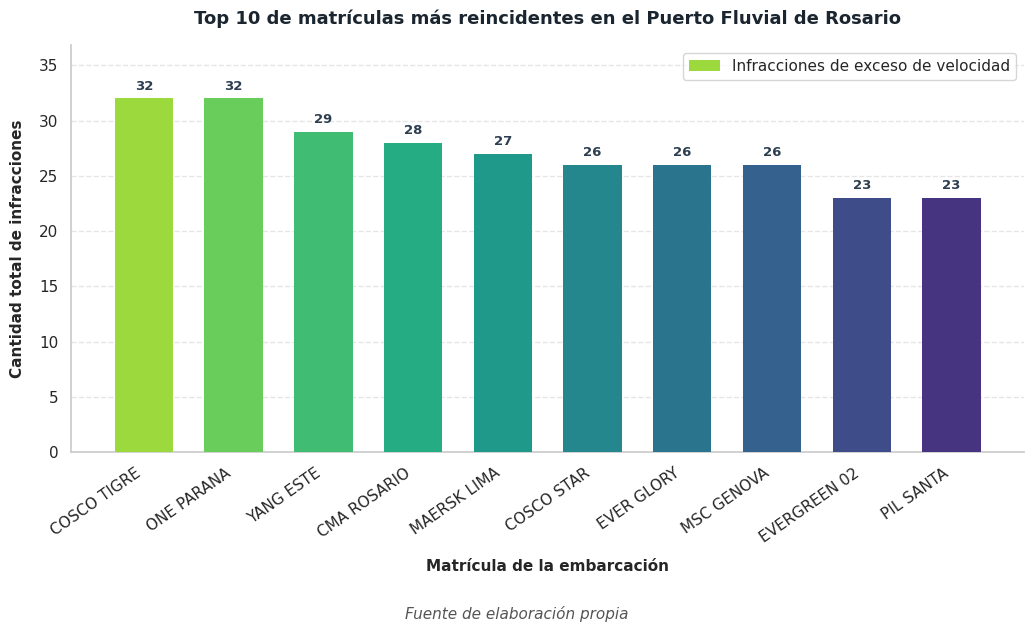

In [ ]:
#@title Top 10 matrículas más reincidentes
top = analizador.top_infractores(TOP_INFRACTORES)

figura, eje = plt.subplots(figsize=(10.5, 6))

mapa_color = plt.cm.viridis_r
colores = [mapa_color(i) for i in np.linspace(0.15, 0.85, len(top))]

barras = eje.bar(
    top["matricula"],
    top["cantidad"],
    color=colores,
    edgecolor="none",
    width=0.65,
    label="Infracciones de exceso de velocidad",
    zorder=3,
)

eje.set_title(
    f"Top {TOP_INFRACTORES} de matrículas más reincidentes en el Puerto "
    "Fluvial de Rosario",
    fontsize=13,
    fontweight="bold",
    pad=15,
    color="#1a252f",
)
eje.set_xlabel("Matrícula de la embarcación", **ESTILO_ETIQUETA_EJE)
eje.set_ylabel("Cantidad total de infracciones", **ESTILO_ETIQUETA_EJE)

eje.bar_label(barras, padding=4, fontsize=9.5, fontweight="bold",
              color="#2c3e50")

eje.tick_params(axis="x", rotation=35)
for etiqueta in eje.get_xticklabels():
    etiqueta.set_horizontalalignment("right")

eje.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)
eje.grid(axis="x", visible=False)

eje.spines["top"].set_visible(False)
eje.spines["right"].set_visible(False)

eje.legend(loc="upper right", frameon=True)
eje.set_ylim(0, top["cantidad"].max() * 1.15)

figura.text(
    0.5, -0.05,
    FUENTE_GRAFICOS,
    ha="center",
    va="bottom",
    fontsize=11,
    fontstyle="italic",
    color="#555555",
)

guardar_y_mostrar(figura, RUTA_GRAFICO_TOP)

- **Total de infracciones por turno del día** (Madrugada / Mañana / Tarde / Noche) en gráfico de torta.

  Exportar: `port_log/data/interim/plots/turnos.jpg`.


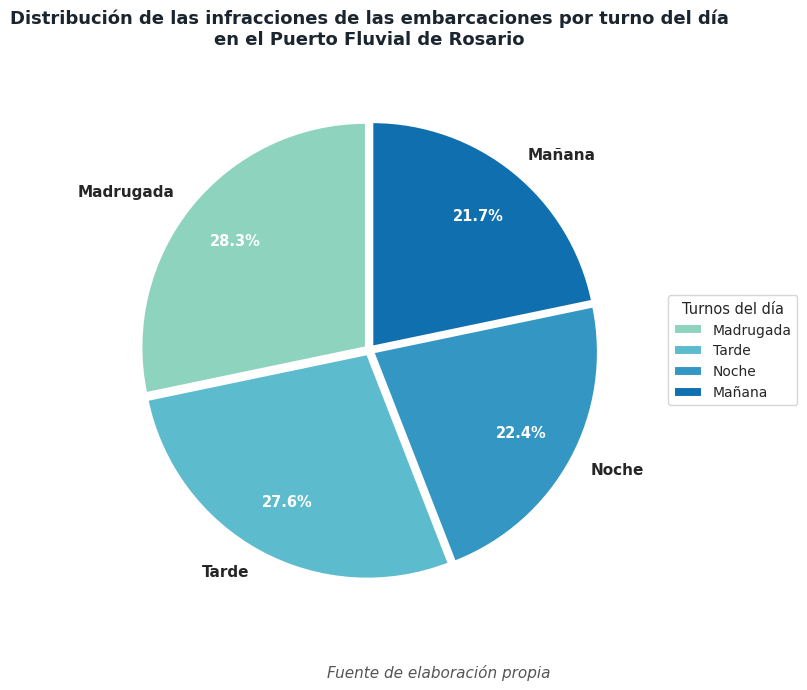

In [ ]:
#@title Total de infracciones por turno del día
por_turno = analizador.infracciones_por_turno()

figura, eje = plt.subplots(figsize=(7.5, 7.5))

mapa_color = plt.cm.GnBu
colores = [mapa_color(i) for i in np.linspace(0.45, 0.85, len(por_turno))]

porciones, textos, autotextos = eje.pie(
    por_turno["cantidad"],
    labels=por_turno["turno"],
    autopct="%1.1f%%",
    pctdistance=0.75,
    startangle=90,
    colors=colores,
    explode=[0.02] * len(por_turno),
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)

for autotexto in autotextos:
    autotexto.set_color("white")
    autotexto.set_fontsize(10.5)
    autotexto.set_fontweight("bold")

for texto in textos:
    texto.set_fontsize(11)
    texto.set_fontweight("semibold")

eje.set_title(
    "Distribución de las infracciones de las embarcaciones por turno del día\n"
    "en el Puerto Fluvial de Rosario",
    fontsize=13,
    fontweight="bold",
    pad=18,
    color="#1a252f",
)

eje.legend(
    title="Turnos del día",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    fontsize=10,
    title_fontsize=10.5,
)

figura.text(
    0.5,
    0.02,
    FUENTE_GRAFICOS,
    ha="center",
    va="bottom",
    fontsize=11,
    fontstyle="italic",
    color="#555555",
)

guardar_y_mostrar(figura, RUTA_GRAFICO_TURNOS)


- **Total de infracciones por mes** en barras horizontal, ordenado de mayor a menor.

  Exportar: `port_log/data/interim/plots/meses.jpg`.


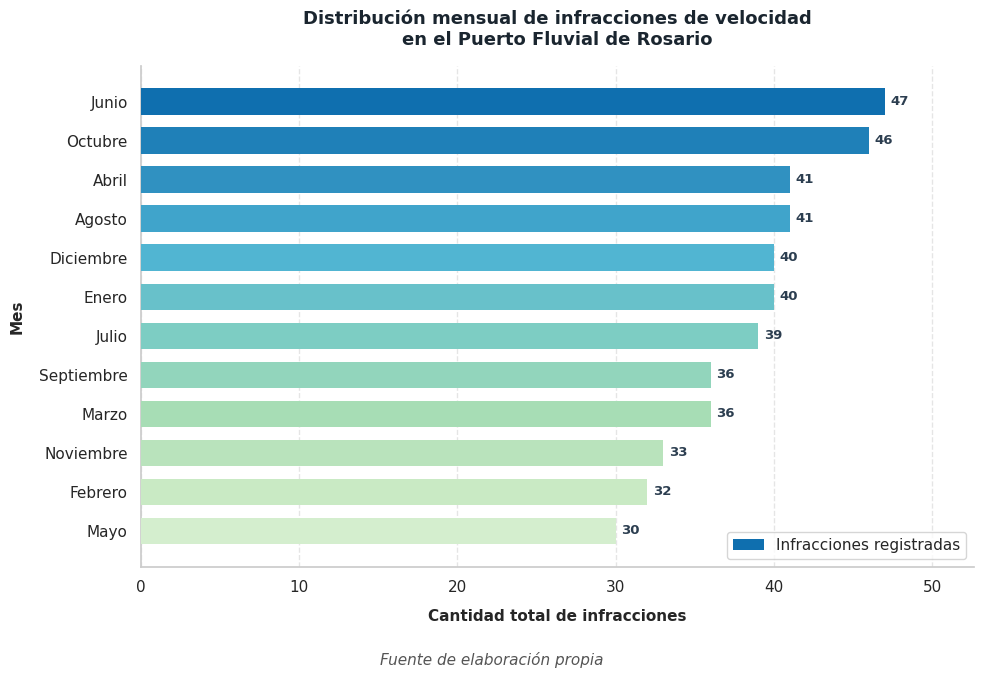

In [ ]:
#@title Total de infracciones por mes
por_mes = analizador.infracciones_por_mes()

figura, eje = plt.subplots(figsize=(10, 6.5))

mapa_color = plt.cm.GnBu_r
colores = [mapa_color(i) for i in np.linspace(0.15, 0.80, len(por_mes))]

barras = eje.barh(
    por_mes["mes"],
    por_mes["cantidad"],
    color=colores,
    edgecolor="none",
    height=0.68,
    label="Infracciones registradas",
    zorder=3,
)

eje.invert_yaxis()

eje.bar_label(
    barras,
    padding=4,
    fontsize=9.5,
    fontweight="bold",
    color="#2c3e50",
)

eje.set_title(
    "Distribución mensual de infracciones de velocidad\n"
    "en el Puerto Fluvial de Rosario",
    fontsize=13,
    fontweight="bold",
    pad=15,
    color="#1a252f",
)

eje.set_xlabel("Cantidad total de infracciones", **ESTILO_ETIQUETA_EJE)
eje.set_ylabel("Mes", **ESTILO_ETIQUETA_EJE)

eje.grid(axis="x", linestyle="--", alpha=0.5, zorder=0)
eje.grid(axis="y", visible=False)
eje.spines["top"].set_visible(False)
eje.spines["right"].set_visible(False)

eje.set_xlim(0, por_mes["cantidad"].max() * 1.12)

eje.legend(loc="lower right", frameon=True)

figura.text(
    0.5, -0.04,
    FUENTE_GRAFICOS,
    ha="center",
    va="bottom",
    fontsize=11,
    fontstyle="italic",
    color="#555555",
)

guardar_y_mostrar(figura, RUTA_GRAFICO_MESES)


- **Histograma del exceso de velocidad real** con curva de densidad (KDE) superpuesta.

  Exportar: `port_log/data/interim/plots/distribucion_exceso.jpg`.


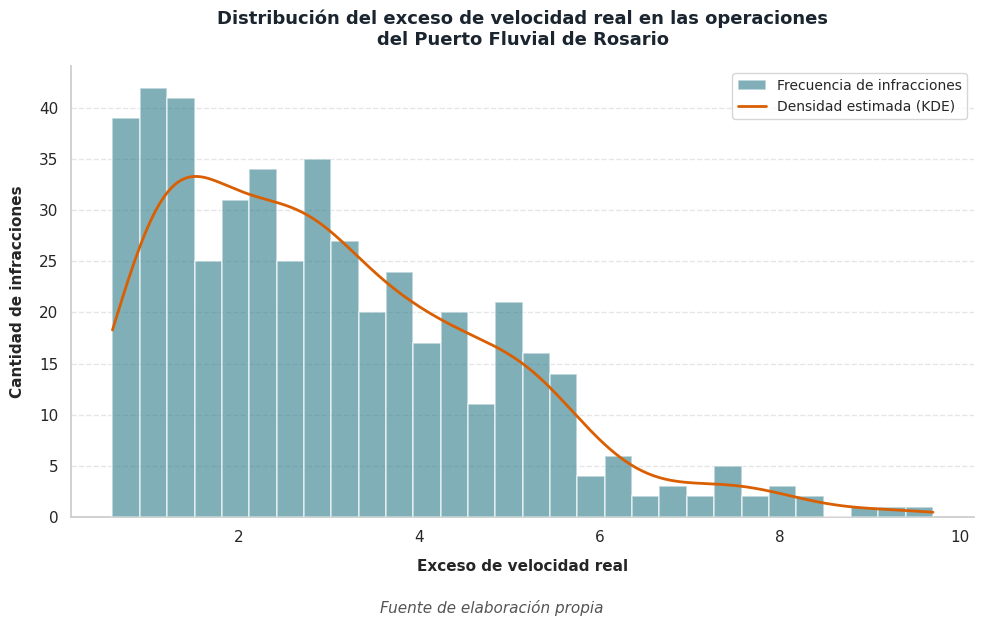

In [ ]:
#@title Histograma del exceso de velocidad real
datos = analizador.infracciones["exceso_velocidad_real"].dropna()

figura, eje = plt.subplots(figsize=(10, 6))

conteos, bordes_bins, parches = eje.hist(
    datos,
    bins=30,
    color="#2b7b8a",
    edgecolor="white",
    linewidth=1.2,
    alpha=0.6,
    label="Frecuencia de infracciones",
    zorder=3,
)

kde = stats.gaussian_kde(datos)
puntos_x = np.linspace(datos.min(), datos.max(), 300)
ancho_bin = bordes_bins[1] - bordes_bins[0]
escala_frecuencia = len(datos) * ancho_bin

eje.plot(
    puntos_x,
    kde(puntos_x) * escala_frecuencia,
    color="#d95f02",
    linewidth=2,
    label="Densidad estimada (KDE)",
    zorder=4,
)

eje.set_title(
    "Distribución del exceso de velocidad real en las operaciones\n"
    "del Puerto Fluvial de Rosario",
    fontsize=13,
    fontweight="bold",
    pad=15,
    color="#1a252f",
)

eje.set_xlabel("Exceso de velocidad real", **ESTILO_ETIQUETA_EJE)
eje.set_ylabel("Cantidad de infracciones", **ESTILO_ETIQUETA_EJE)

eje.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)
eje.grid(axis="x", visible=False)
eje.spines["top"].set_visible(False)
eje.spines["right"].set_visible(False)

eje.legend(loc="upper right", frameon=True, fontsize=10)

figura.text(
    0.5, -0.04,
    FUENTE_GRAFICOS,
    ha="center",
    va="bottom",
    fontsize=11,
    fontstyle="italic",
    color="#555555",
)

guardar_y_mostrar(figura, RUTA_GRAFICO_EXCESO)


- **Exceso de velocidad promedio por muelle** en barras horizontal, ordenado de mayor a menor.

  Exportar: `port_log/data/interim/plots/exceso_por_muelle.jpg`.


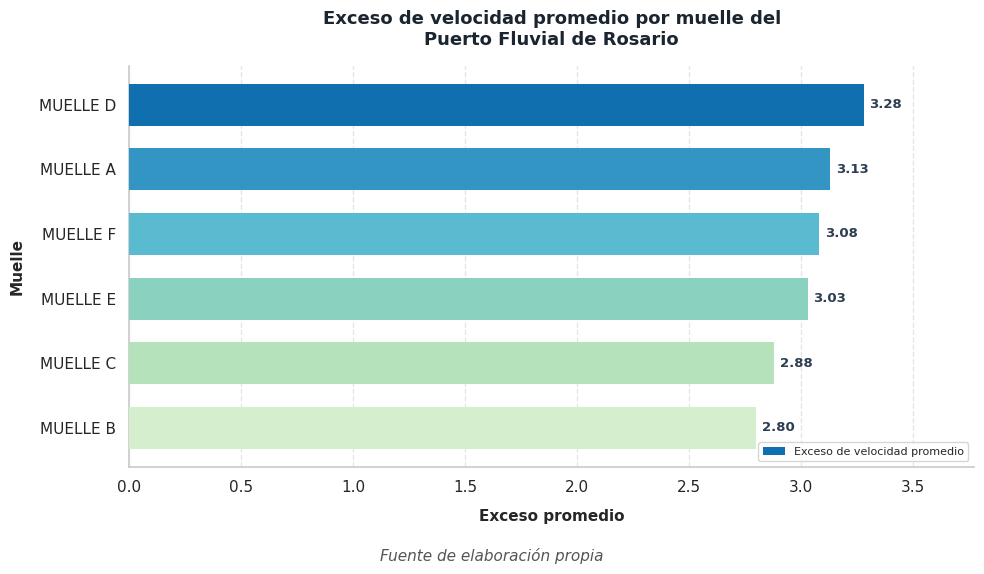

In [ ]:
#@title Exceso de velocidad promedio por muelle
por_muelle = analizador.exceso_promedio_por_muelle()

figura, eje = plt.subplots(figsize=(10, 5.5))

mapa_color = plt.cm.GnBu_r
colores = [mapa_color(i) for i in np.linspace(0.15, 0.80, len(por_muelle))]

barras = eje.barh(
    por_muelle["muelle"],
    por_muelle["exceso_promedio"],
    color=colores,
    edgecolor="none",
    height=0.65,
    label="Exceso de velocidad promedio",
    zorder=3,
)

eje.invert_yaxis()

eje.bar_label(
    barras,
    fmt="%.2f",
    padding=4,
    fontsize=9.5,
    fontweight="bold",
    color="#2c3e50",
)

eje.set_title(
    "Exceso de velocidad promedio por muelle del\n"
    "Puerto Fluvial de Rosario",
    fontsize=13,
    fontweight="bold",
    pad=15,
    color="#1a252f",
)

eje.set_xlabel(
    "Exceso promedio", **ESTILO_ETIQUETA_EJE
)
eje.set_ylabel(
    "Muelle", **ESTILO_ETIQUETA_EJE
)

eje.grid(axis="x", linestyle="--", alpha=0.5, zorder=0)
eje.grid(axis="y", visible=False)
eje.spines["top"].set_visible(False)
eje.spines["right"].set_visible(False)

eje.set_xlim(0, por_muelle["exceso_promedio"].max() * 1.15)

eje.legend(loc="lower right", frameon=True, fontsize=8)

figura.text(
    0.5,
    -0.04,
    FUENTE_GRAFICOS,
    ha="center",
    va="bottom",
    fontsize=11,
    fontstyle="italic",
    color="#555555",
)

guardar_y_mostrar(figura, RUTA_GRAFICO_MUELLES)


- **Comparación de infracciones con fecha válida vs fecha inválida (`1900-01-01`)** en barras simple.

  Exportar: `port_log/data/interim/plots/fechas_invalidas.jpg`.

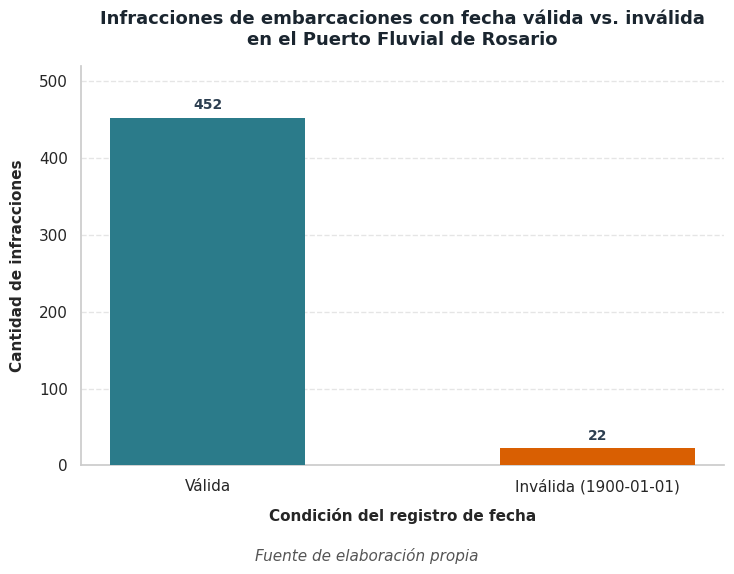

In [ ]:
#@title Infracciones con fecha válida vs fecha inválida
por_validez = analizador.infracciones_por_validez_fecha()

figura, eje = plt.subplots(figsize=(7.5, 5.5))

if len(por_validez) == 2:
    colores = ["#2b7b8a", "#d95f02"]
else:
    mapa_color = plt.cm.GnBu_r
    colores = [mapa_color(i)
               for i in np.linspace(0.15, 0.80, len(por_validez))]

barras = eje.bar(
    por_validez["fecha"],
    por_validez["cantidad"],
    color=colores,
    edgecolor="none",
    width=0.5,
    label="Registros de infracción",
    zorder=3,
)

eje.bar_label(
    barras,
    padding=4,
    fontsize=10,
    fontweight="bold",
    color="#2c3e50",
)

eje.set_title(
    "Infracciones de embarcaciones con fecha válida vs. inválida\n"
    "en el Puerto Fluvial de Rosario",
    fontsize=13,
    fontweight="bold",
    pad=15,
    color="#1a252f",
)

eje.set_xlabel("Condición del registro de fecha", **ESTILO_ETIQUETA_EJE)
eje.set_ylabel("Cantidad de infracciones", **ESTILO_ETIQUETA_EJE)

eje.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)
eje.grid(axis="x", visible=False)
eje.spines["top"].set_visible(False)
eje.spines["right"].set_visible(False)

eje.set_ylim(0, por_validez["cantidad"].max() * 1.15)

figura.text(
    0.5, -0.04,
    FUENTE_GRAFICOS,
    ha="center",
    va="bottom",
    fontsize=11,
    fontstyle="italic",
    color="#555555",
)

guardar_y_mostrar(figura, RUTA_GRAFICO_FECHAS)

In [ ]:
#@title Registrar el Día 5 en git
registrar_dia(
    5,
    "Gráficos de infracciones",
    [
        "Top 10 de matrículas reincidentes (barras verticales).",
        "Infracciones por turno del día (torta).",
        "Infracciones por mes (barras horizontales).",
        "Histograma del exceso de velocidad real con KDE.",
        "Exceso promedio por muelle (barras horizontales).",
        "Infracciones con fecha válida vs inválida (barras).",
    ],
    [RUTA_GRAFICO_TOP, RUTA_GRAFICO_TURNOS, RUTA_GRAFICO_MESES,
     RUTA_GRAFICO_EXCESO, RUTA_GRAFICO_MUELLES, RUTA_GRAFICO_FECHAS],
)

[GIT] Commit 'Día 5: Gráficos de infracciones' creado.
[GIT] Push desactivado: el commit queda solo en local.


## Ejercicio 06

> Puntos: 1

Responder las siguientes preguntas con el dataset limpio:

- ¿Qué porcentaje de infracciones provienen de registros con fecha inválida?
```
El porcentaje de infracciones con fecha inválida es XX.XX%
```



In [ ]:
#@title Porcentaje de infracciones con fecha inválida
print("El porcentaje de infracciones con fecha inválida es "
      f"{analizador.porcentaje_fecha_invalida():.2f}%")

El porcentaje de infracciones con fecha inválida es 4.64%


- ¿Qué porcentaje de infracciones provienen de registros con hora inválida?
```
El porcentaje de infracciones con hora inválida es XX.XX%
```


In [ ]:
#@title Porcentaje de infracciones con hora inválida
print("El porcentaje de infracciones con hora inválida es "
      f"{analizador.porcentaje_hora_invalida():.2f}%")

El porcentaje de infracciones con hora inválida es 18.57%



- ¿Cuál es el tipo de carga más frecuente en infracciones y qué porcentaje representa?
```
El tipo de carga más frecuente es XXXX con XX.XX%
```


In [ ]:
#@title Tipo de carga más frecuente en infracciones
por_carga = analizador.infractores_por_tipo_carga()
carga_frecuente = por_carga.iloc[0]
porcentaje_carga = (carga_frecuente["cantidad"]
                    / analizador.total_infracciones * 100)
print(f"El tipo de carga más frecuente es {carga_frecuente['tipo_carga']} "
      f"con {porcentaje_carga:.2f}%")

El tipo de carga más frecuente es CONTENEDORES con 14.98%



- ¿Cuál es el origen más frecuente entre los buques infractores?
```
El origen más frecuente entre infractores es XXXX con XX registros.
```

In [ ]:
#@title Origen más frecuente entre infractores
origen, registros_origen = analizador.origen_mas_frecuente()
print(f"El origen más frecuente entre infractores es {origen} con "
      f"{registros_origen} registros.")

El origen más frecuente entre infractores es VALPARAISO con 71 registros.




- ¿Cuál es la duración promedio de estadía en muelle de los buques infractores?
```
La duración promedio de estadía de buques infractores es XX.XX horas.
```

In [ ]:
#@title Duración promedio de estadía de infractores
print("La duración promedio de estadía de buques infractores es "
      f"{analizador.duracion_promedio():.2f} horas.")

La duración promedio de estadía de buques infractores es 40.06 horas.


In [ ]:
#@title Registrar el Día 6 en git
registrar_dia(
    6,
    "Preguntas de negocio sobre el dataset limpio",
    [
        "Porcentaje de infracciones con fecha inválida y con hora inválida.",
        "Tipo de carga más frecuente entre las infracciones.",
        "Origen más frecuente entre los buques infractores.",
        "Duración promedio de estadía de los buques infractores.",
    ],
)

[GIT] Día 6: no hay cambios nuevos para commitear.


## Ejercicio 07

> Puntos: 1

Redactar una conclusión que incluya:

- Evaluación de la calidad del dataset heredado: porcentaje de registros descartados y tipos de error más frecuentes.
- Patrones de infracción detectados: ¿en qué turnos, muelles y tipos de carga se concentran?
- Reflexión sobre el impacto de incorporar estos datos sin limpieza previa al nuevo sistema.
- Al menos una propuesta concreta de mejora para el proceso de captura de datos en el puerto.

Guardar la conclusión en `port_log/reports/conclusion.md`

In [ ]:
#@title Conclusión del sprint
def listar(elementos: Iterable[str]) -> str:
    """Une elementos en una enumeración legible en castellano."""
    elementos = list(elementos)
    if len(elementos) <= 1:
        return "".join(elementos)
    return f"{', '.join(elementos[:-1])} y {elementos[-1]}"


total_crudo = len(df_raw)
descartados_calidad = (sum(eliminadas_por_nulos.values())
                       + sum(eliminadas_por_outliers.values()))
errores_por_columna = ((100 - completitud) / 100 * total_crudo).round()
errores_frecuentes = errores_por_columna[errores_por_columna.gt(0)].nlargest(3)
turno_principal = analizador.infracciones_por_turno().iloc[0]
muelles_principales = analizador.infracciones_por_muelle().nlargest(
    2, "cantidad")
muelle_mas_rapido = analizador.exceso_promedio_por_muelle().iloc[0]
carga_principal = analizador.infractores_por_tipo_carga().iloc[0]

lineas_conclusion = [
    f"# Conclusión - {SPRINT_ACTUAL}",
    "",
    "## Calidad del dataset heredado",
    "",
    f"- Se recibieron {total_crudo} registros. Por problemas de calidad "
    "(nulos en columnas críticas y outliers) se descartaron "
    f"{descartados_calidad} ({descartados_calidad / total_crudo:.2%}); "
    f"otros {filas_sin_infraccion} se excluyeron por no constituir "
    f"infracción, quedando {analizador.total_infracciones} infracciones.",
    "- Los errores más frecuentes por columna son:",
    *[f"  - `{columna}`: {int(cantidad)} valores incorrectos "
      f"({100 - completitud[columna]:.2f}%)"
      for columna, cantidad in errores_frecuentes.items()],
    f"- Entre las infracciones, {analizador.porcentaje_fecha_invalida():.2f}%"
    f" tiene una fecha inválida y {analizador.porcentaje_hora_invalida():.2f}%"
    " una hora inválida: son datos que el nuevo sistema no podría ubicar en "
    "el tiempo.",
    "",
    "## Patrones de infracción",
    "",
    f"- Turno con más infracciones: **{turno_principal['turno']}** "
    f"({turno_principal['cantidad']} casos). Las horas inválidas se "
    f"completaron con {HORA_INVALIDA}, así que parte de ese turno puede ser "
    "un efecto de la limpieza y no un patrón real.",
    "- Muelles con más infracciones: " + listar(
        f"**{fila.muelle}** ({fila.cantidad})"
        for fila in muelles_principales.itertuples())
    + f". El mayor exceso promedio se da en **{muelle_mas_rapido['muelle']}**"
    f" ({muelle_mas_rapido['exceso_promedio']:.2f}).",
    "- Tipo de carga con más infracciones: "
    f"**{carga_principal['tipo_carga']}** ({carga_principal['cantidad']} "
    "casos).",
    f"- Exceso promedio: {analizador.exceso_promedio():.2f} sin tolerancia y "
    f"{analizador.exceso_promedio_tolerancia():.2f} con la tolerancia del "
    f"{TOLERANCIA_VELOCIDAD:.0%}.",
    "",
    "## Impacto de migrar sin limpieza",
    "",
    "Cargar estos datos sin depurar llevaría al nuevo sistema velocidades y "
    "tonelajes imposibles que distorsionan cualquier promedio, estadías "
    "negativas o de siglos por fechas mal cargadas, y el mismo buque "
    "repartido en varias matrículas escritas de forma distinta. Las "
    "sanciones y los reportes de reincidencia quedarían mal atribuidos y las "
    "decisiones operativas se tomarían sobre indicadores falsos.",
    "",
    "## Propuestas de mejora para la captura de datos",
    "",
    "1. Validar en el punto de carga: fecha y hora con selector (ISO 8601 y "
    "24 hs), rangos numéricos por muelle y tipo de carga, y campos "
    "obligatorios que no permitan guardar el registro vacío.",
    "2. Tomar matrícula y muelle de catálogos maestros en lugar de texto "
    "libre, así un mismo buque no aparece con varias grafías.",
    "3. Registrar la velocidad directamente desde el radar (`radar_id`) con "
    "marca de tiempo automática, eliminando la transcripción manual.",
]
conclusion = "\n".join(lineas_conclusion) + "\n"

RUTA_CONCLUSION.parent.mkdir(parents=True, exist_ok=True)
RUTA_CONCLUSION.write_text(conclusion, encoding="utf-8")
display(Markdown(conclusion))

# Conclusión - Sprint 1

## Calidad del dataset heredado

- Se recibieron 1500 registros. Por problemas de calidad (nulos en columnas críticas y outliers) se descartaron 255 (17.00%); otros 772 se excluyeron por no constituir infracción, quedando 474 infracciones.
- Los errores más frecuentes por columna son:
  - `hora_egreso`: 171 valores incorrectos (11.40%)
  - `matricula`: 142 valores incorrectos (9.47%)
  - `hora_ingreso`: 97 valores incorrectos (6.47%)
- Entre las infracciones, 4.64% tiene una fecha inválida y 18.57% una hora inválida: son datos que el nuevo sistema no podría ubicar en el tiempo.

## Patrones de infracción

- Turno con más infracciones: **Madrugada** (134 casos). Las horas inválidas se completaron con 00:00, así que parte de ese turno puede ser un efecto de la limpieza y no un patrón real.
- Muelles con más infracciones: **MUELLE D** (87) y **MUELLE B** (82). El mayor exceso promedio se da en **MUELLE D** (3.28).
- Tipo de carga con más infracciones: **CONTENEDORES** (71 casos).
- Exceso promedio: 3.03 sin tolerancia y 2.47 con la tolerancia del 5%.

## Impacto de migrar sin limpieza

Cargar estos datos sin depurar llevaría al nuevo sistema velocidades y tonelajes imposibles que distorsionan cualquier promedio, estadías negativas o de siglos por fechas mal cargadas, y el mismo buque repartido en varias matrículas escritas de forma distinta. Las sanciones y los reportes de reincidencia quedarían mal atribuidos y las decisiones operativas se tomarían sobre indicadores falsos.

## Propuestas de mejora para la captura de datos

1. Validar en el punto de carga: fecha y hora con selector (ISO 8601 y 24 hs), rangos numéricos por muelle y tipo de carga, y campos obligatorios que no permitan guardar el registro vacío.
2. Tomar matrícula y muelle de catálogos maestros en lugar de texto libre, así un mismo buque no aparece con varias grafías.
3. Registrar la velocidad directamente desde el radar (`radar_id`) con marca de tiempo automática, eliminando la transcripción manual.


In [ ]:
#@title Registrar el Día 7 en git
registrar_dia(
    7,
    "Conclusión del sprint",
    [
        "Conclusión en `reports/conclusion.md` generada a partir de los "
        "resultados: calidad del dataset, patrones de infracción, impacto "
        "de migrar sin limpieza y propuestas de mejora.",
    ],
    [RUTA_CONCLUSION],
)

[GIT] Día 7: no hay cambios nuevos para commitear.


---

# CHECKS

`De aquí en adelante solo ejecutar`

## Visualizar la rama actual

In [ ]:
!git status

On branch Sprint_1
Your branch is ahead of 'origin/Sprint_1' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


## Visualizar el contenido de cada commit

In [ ]:
!git --no-pager log --name-status Sprint_1

commit 1a7b57c969cecc03c7702794d56d8ea6f47d476a (HEAD -> Sprint_1)
Author: Melina Lopez <227845157+meliilopez@users.noreply.github.com>
Date:   Wed Sep 23 22:22:42 2026 +0000

    Día 5: Gráficos de infracciones

M	port_log/data/interim/plots/distribucion_exceso.jpg
M	port_log/data/interim/plots/exceso_por_muelle.jpg
M	port_log/data/interim/plots/fechas_invalidas.jpg
M	port_log/data/interim/plots/meses.jpg
M	port_log/data/interim/plots/top_infractores.jpg
M	port_log/data/interim/plots/turnos.jpg

commit 3c776398c490ba66a15510a163072270ace31607 (origin/Sprint_1, origin/HEAD)
Author: gustavomzapana <166059004+gustavomzapana@users.noreply.github.com>
Date:   Wed Sep 23 17:59:09 2026 -0400

    Día 7: Conclusión del sprint

M	CHANGELOG.md
A	port_log/reports/conclusion.md

commit c5b32e1acba0efafdd772e4fc7f45102132aae95
Author: Melina Lopez <227845157+meliilopez@users.noreply.github.com>
Date:   Wed Sep 23 17:57:43 2026 -0400

    Día 6: Preguntas de negocio sobre el dataset limpio

M	CHANG